In [101]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

!pip install scikit-learn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC



[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [102]:
df=pd.read_csv('C:/Users/MG/Desktop/AI/ui/customer_churn.csv')
df.head()

,age,monthly_charges,tenure_months,support_calls,satisfaction_score,total_spent,churn
0,45.0,76.18,36,3,5.0,NaN,0
1,40.0,32.96,66,9,NaN,85.65,0
2,48.0,62.68,54,4,NaN,5008.40,1
3,51.0,49.92,42,6,NaN,2200.15,0
4,39.0,80.16,36,7,NaN,1708.61,1


In [103]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   age                 561 non-null    float64
 1   monthly_charges     544 non-null    float64
 2   tenure_months       600 non-null    int64  
 3   support_calls       600 non-null    int64  
 4   satisfaction_score  536 non-null    float64
 5   total_spent         550 non-null    float64
 6   churn               600 non-null    int64  
dtypes: float64(4), int64(3)
memory usage: 32.9 KB


In [104]:
df.shape

(600, 7)

In [105]:
df.describe()

,age,monthly_charges,tenure_months,support_calls,satisfaction_score,total_spent,churn
count,561.000000,544.000000,600.000000,600.000000,536.000000,550.000000,600.000000
mean,48.417112,69.943254,40.503333,4.481667,5.501866,3972.465291,0.493333
std,8.727870,19.141093,12.296286,1.794909,1.609550,1545.381274,0.500373
min,18.000000,20.000000,0.000000,0.000000,1.000000,0.000000,0.000000
25%,44.000000,55.940000,33.000000,3.000000,4.000000,2823.120000,0.000000
50%,50.000000,71.915000,42.000000,4.000000,5.000000,3931.035000,0.000000
75%,54.000000,84.675000,49.000000,6.000000,7.000000,5047.377500,1.000000
max,70.000000,120.000000,72.000000,10.000000,10.000000,8000.000000,1.000000


In [106]:
df['churn'].value_counts()

churn
0    304
1    296
Name: count, dtype: int64

# **Data Cleaning**

In [107]:
df.isnull().sum()

age                   39
monthly_charges       56
tenure_months          0
support_calls          0
satisfaction_score    64
total_spent           50
churn                  0
dtype: int64

In [108]:
df['age']=df['age'].fillna(df['age'].median())
df['satisfaction_score']=df['satisfaction_score'].fillna(df['satisfaction_score'].median())
df['monthly_charges']= df['monthly_charges'].fillna(df['monthly_charges'].median())
df['total_spent']=df['total_spent'].fillna(df['total_spent'].median())
df.isnull().sum()

age                   0
monthly_charges       0
tenure_months         0
support_calls         0
satisfaction_score    0
total_spent           0
churn                 0
dtype: int64

In [109]:
df.duplicated().sum()

np.int64(0)

In [110]:
num_cols = ['age', 'satisfaction_score', 'monthly_charges', 'total_spent','churn','tenure_months','support_calls']
q1=df[num_cols].quantile(0.25)
q3=df[num_cols].quantile(0.75)
iqr=q3-q1
lower_bound=q1-(1.5*iqr)
upper_bound=q3+(1.5*iqr)
outlier = df[(df[num_cols] < lower_bound) | (df[num_cols] > upper_bound)]
print(outlier.sum())
print(df.shape)

print(lower_bound)
print(upper_bound)


age                   437.00
monthly_charges       379.15
tenure_months          12.00
support_calls           0.00
satisfaction_score    722.00
total_spent             0.00
churn                   0.00
dtype: float64
(600, 7)
age                    29.00000
satisfaction_score      3.50000
monthly_charges        22.37000
total_spent          -157.65625
churn                  -1.50000
tenure_months           9.00000
support_calls          -1.50000
dtype: float64
age                     69.00000
satisfaction_score       7.50000
monthly_charges        119.49000
total_spent           8029.47375
churn                    2.50000
tenure_months           73.00000
support_calls           10.50000
dtype: float64


# Visualization

<Axes: xlabel='monthly_charges'>

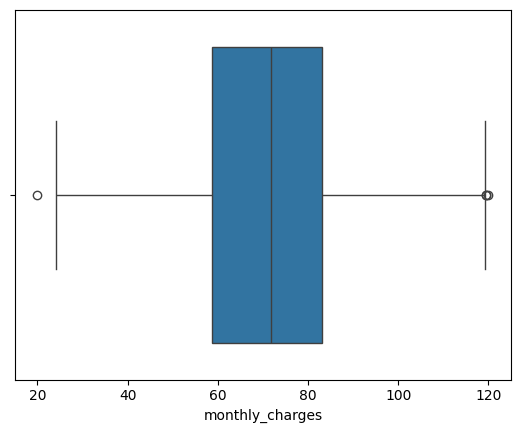

In [111]:
sns.boxplot(x=df['monthly_charges'])

In [112]:
q1 = df['monthly_charges'].quantile(0.25)
q3 = df['monthly_charges'].quantile(0.75)
IQR =q3-q1
lower_bound =q1-1.5* IQR
upper_bound = q3+1.5*IQR
df['monthly_charges']= df['monthly_charges'].clip(lower=lower_bound, upper=upper_bound)

<Axes: xlabel='monthly_charges'>

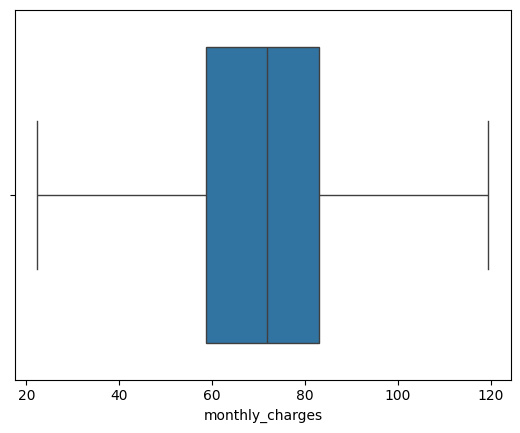

In [113]:
sns.boxplot(x=df['monthly_charges'])

Text(0.5, 1.0, 'Correlation Heatmap')

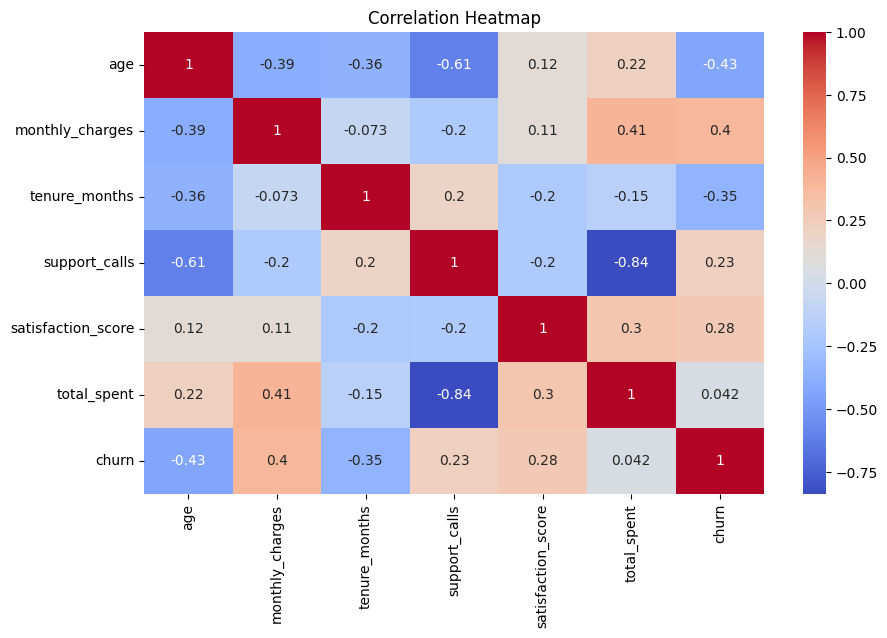

In [114]:
plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')

Text(0, 0.5, 'Count')

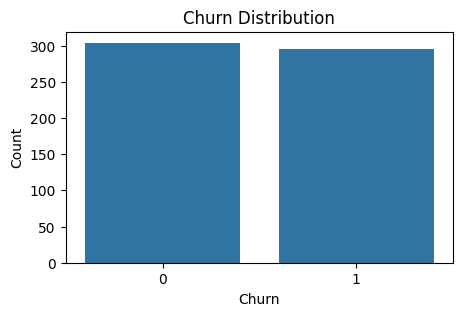

In [115]:
plt.figure(figsize=(5, 3))
sns.countplot(x='churn', data=df)
plt.title('Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Count')

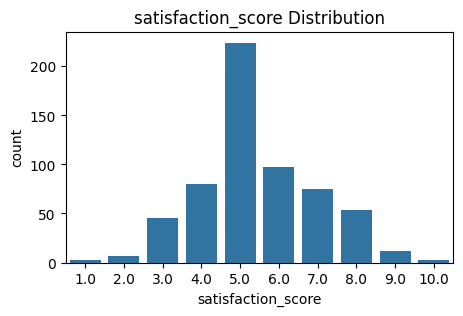

In [116]:
plt.figure(figsize=(5, 3))
sns.countplot(x='satisfaction_score', data=df)
plt.title('satisfaction_score Distribution')
plt.show()

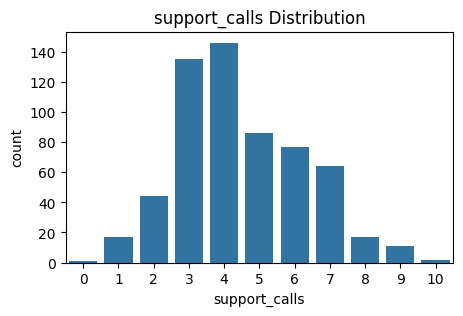

In [117]:
plt.figure(figsize=(5, 3))
sns.countplot(x='support_calls', data=df)
plt.title('support_calls Distribution')
plt.show()

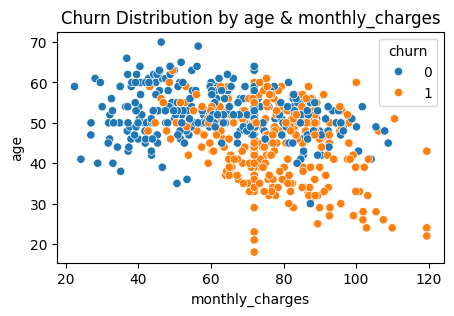

In [118]:
plt.figure(figsize=(5, 3))
sns.scatterplot(x='monthly_charges',y='age', data=df, hue='churn')
plt.title('Churn Distribution by age & monthly_charges')
plt.show()

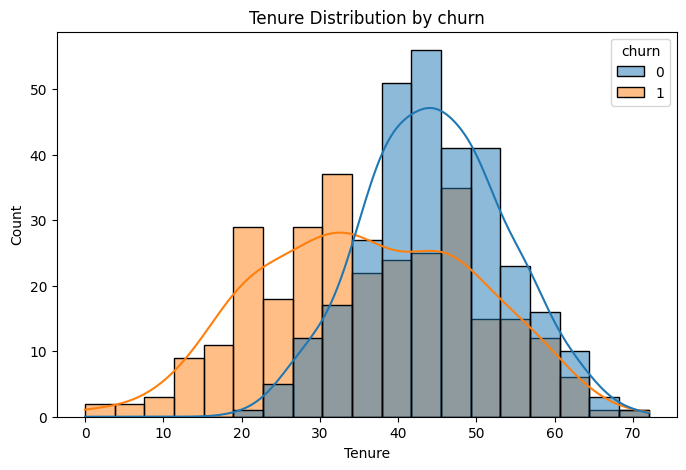

In [119]:
plt.figure(figsize=(8,5))
sns.histplot ( x='tenure_months', data=df ,hue='churn', kde=True)
plt.title('Tenure Distribution by churn')
plt.xlabel('Tenure')
plt.ylabel('Count')
plt.show()

# **Split **

In [120]:
x =df.drop('churn', axis=1)
y =df['churn']

In [121]:
x_train, x_test , y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=42)


# **Preprocessing**

In [122]:
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

# **MODEL**

In [123]:
model= LogisticRegression(max_iter=1000 ,random_state=42)
model.fit(x_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [124]:
%pip install joblip

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement joblip (from versions: none)

[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for joblip


In [125]:
import pickle
with open ('model.pkl','wb')as file:
    pickle.dump(model,file)
print("model saved successfully!")

model saved successfully!


## **Evaluation**

In [126]:
y_pred = model.predict(x_test)
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
print(classification_report(y_test, y_pred))

Accuracy: 0.875
              precision    recall  f1-score   support

           0       0.81      0.92      0.86        51
           1       0.94      0.84      0.89        69

    accuracy                           0.88       120
   macro avg       0.87      0.88      0.87       120
weighted avg       0.88      0.88      0.88       120



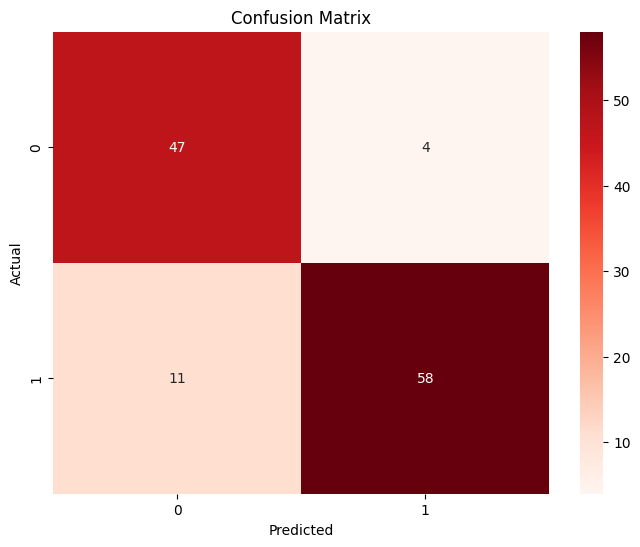

In [127]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Reds')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [128]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(model, x_train, y_train, cv=5)
print(f'Cross-Validation Scores: {cv_scores}')

Cross-Validation Scores: [0.89583333 0.875      0.91666667 0.82291667 0.875     ]


In [129]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)
rf_y_pred = rf_model.predict(x_test)
rf_accuracy = accuracy_score(y_test, rf_y_pred)
print(f'Random Forest Accuracy: {rf_accuracy}')
print(classification_report(y_test, rf_y_pred))


Random Forest Accuracy: 0.8416666666666667
              precision    recall  f1-score   support

           0       0.77      0.90      0.83        51
           1       0.92      0.80      0.85        69

    accuracy                           0.84       120
   macro avg       0.84      0.85      0.84       120
weighted avg       0.85      0.84      0.84       120



In [135]:
import pickle
import os

model_path = r"C:/Users/MG/Desktop/AI/ui/model.pkl"
with open(model_path ,'wb') as file:
    pickle.dump(model, file)
print("model saved successfully in ui folder!")

model saved successfully in ui folder!


In [130]:
%pip install joblip scikit-learn

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement joblip (from versions: none)

[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for joblip


In [131]:
!pip install gradio


[notice] A new release of pip is available: 24.3.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [132]:
import gradio as gr

In [133]:
def predict(age, monthly_charges, tenure_months,
            support_calls, satisfaction_score, total_spent):
    row = {'age': age, 'monthly_charges': monthly_charges,
           'tenure_months': tenure_months, 'support_calls': support_calls,
           'satisfaction_score': satisfaction_score, 'total_spent': total_spent}
    x_input = pd.DataFrame([row], columns=x.columns)
    x_scaled = scaler.transform(x_input)
    prob = model.predict_proba(x_scaled)[0][1]
    label = '⚠️ على الأغلب هيمشي (Churn)' if prob >= 0.5 else '✅ على الأغلب هيكمل'
    return label, f'{prob:.1%}'

demo = gr.Interface(
    fn=predict,
    inputs=[
        gr.Slider(18, 80, value=40, label='Age'),
        gr.Slider(15, 120, value=60, label='Monthly Charges'),
        gr.Slider(0, 73, value=24, label='Tenure (months)'),
        gr.Slider(0, 10, value=3, step=1, label='Support Calls'),
        gr.Slider(1, 10, value=5, step=1, label='Satisfaction Score'),
        gr.Slider(0, 8000, value=1500, label='Total Spent'),
    ],
    outputs=[gr.Textbox(label='النتيجة'),
             gr.Textbox(label='احتمال الـ Churn')],
    title='Customer Churn Predictor',
    description='ادخلي بيانات العميل وشوفي احتمال إنه يغادر.'
)

demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7862
* Running on public URL: https://5f86a8eb4e092099cc.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
